# Model 1: Fine-tuned Wav2Vec 2.0

`facebook/wav2vec2-base` fine-tuned on the raw 3-second waveforms. The convolutional feature
encoder is frozen and the transformer layers and classification head are trained. Code shared with
the other notebooks is in `common.ipynb`.

In [1]:
import json
import math

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from matplotlib import pyplot as plt
from sklearn.utils.class_weight import compute_class_weight
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm
from transformers import (Wav2Vec2FeatureExtractor, Wav2Vec2ForSequenceClassification,
                          get_linear_schedule_with_warmup)

%run common.ipynb  # shared settings and helper functions

MODEL_NAME = "facebook/wav2vec2-base"
BATCH_SIZE = 8          # largest that fits on the 8 GB RTX 3070
GRAD_ACCUM_STEPS = 4    # 8 x 4 = effective batch size of 32
LEARNING_RATE = 2.5e-5
MAX_EPOCHS = 20
PATIENCE = 3            # epochs without a better dev score before stopping
NUM_WORKERS = 0         # keep at 0 on Windows: worker processes can't load a Dataset class
                        # defined inside a notebook, and the DataLoader hangs forever

# The three fine-tuning recipes compared in section 5.
#   v1: the recipe from the methodology.
#   v2: v1 + weighted sum of all layers, LR warmup/decay, augmentation, stronger masking.
#       This one failed to train (see section 5).
#   v3: v1 + augmentation, stronger masking and a dev check every half epoch.
# eval_every_clips=4352 is about half an epoch of the full training set. train_clips (v2 only)
# fixes the total number of clips seen, so oversampling's bigger epochs don't get extra updates.
RECIPES = {
    "v1": dict(weighted_layer_sum=False, warmup_ratio=None, augment=False,
               mask_time_prob=0.05, mask_feature_prob=0.0,
               train_clips=None, eval_every_clips=None, patience_evals=PATIENCE),
    "v2": dict(weighted_layer_sum=True, warmup_ratio=0.1, augment=True,
               mask_time_prob=0.10, mask_feature_prob=0.05,
               train_clips=8 * 8708, eval_every_clips=4352, patience_evals=2 * PATIENCE),
    "v3": dict(weighted_layer_sum=False, warmup_ratio=None, augment=True,
               mask_time_prob=0.10, mask_feature_prob=0.05,
               train_clips=None, eval_every_clips=4352, patience_evals=2 * PATIENCE),
}

# Each run takes 0.5-1.5 hours. If a run's checkpoint is already in feature_cache/ it is reused.
# Set to False to retrain everything.
REUSE_CHECKPOINTS = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"  # mixed precision on the GPU
print(f"Device: {DEVICE}")

torch.manual_seed(SEED)
np.random.seed(SEED)

Device: cuda


## 1. Labels

Same labels and splits as Models 2 and 3 (`load_clips` in `common.ipynb`).

In [2]:
clips = load_clips()
train_df, dev_df, test_df = split_clips(clips)

print(f"Usable clips: {len(clips)}")
print(f"Train: {len(train_df)}, Dev: {len(dev_df)}, Test: {len(test_df)}")
print_class_counts(train_df["label"], "\nTraining set class distribution (before resampling):")

Usable clips: 14930
Train: 8708, Dev: 3001, Test: 3221

Training set class distribution (before resampling):
  0 Prolongation: 762
  1 Block: 814
  2 SoundRep: 543
  3 WordRep: 913
  4 Interjection: 1588
  5 NoStutteredWords: 4088


## 2. Waveforms

Same clip extraction as Models 2 and 3, but no MFCCs, because Wav2Vec 2.0 takes the raw waveform.
The waveforms are cached as float32 (about 190 KB per clip).

In [3]:
def waveforms(df, name):
    return cached(f"Xwav_{name}_wav2vec_wav_v1", f"ywav_{name}_wav2vec_wav_v1",
                  lambda: (np.stack(list(sep28k_clips(df, name))), df["label"].to_numpy()))


wav_train, y_train = waveforms(train_df, "train")
wav_dev, y_dev = waveforms(dev_df, "dev")
wav_test, y_test = waveforms(test_df, "test")

print(f"\nTrain: {wav_train.shape}, Dev: {wav_dev.shape}, Test: {wav_test.shape}")

Xwav_train_wav2vec_wav_v1: loaded from cache


Xwav_dev_wav2vec_wav_v1: loaded from cache
Xwav_test_wav2vec_wav_v1: loaded from cache



Train: (8708, 48000), Dev: (3001, 48000), Test: (3221, 48000)


## 3. Dataset and augmentation

The feature extractor normalises each clip to zero mean and unit variance, which is how the model
was pre-trained. Everything else happens inside the model.

Recipes v2 and v3 augment the training clips on the fly (never dev, test or UCLASS). Each step is
applied with probability 0.5:
- **Speed change** of 0.9-1.1x. This also shifts pitch, so it roughly imitates different speaking
  rates and vocal tract lengths, which matters for timing-based stutters and for child speech.
- **White noise** at 15-40 dB SNR, for different recording conditions.
- **Time shift** of up to 0.25 s, padded with zeros.

Volume isn't augmented because the normalisation would undo it.

In [4]:
feature_extractor = Wav2Vec2FeatureExtractor.from_pretrained(MODEL_NAME)


class WaveformDataset(Dataset):
    """The rows of `waveforms` listed in `indices`. Indices can repeat (oversampling),
    and nothing is copied."""

    def __init__(self, waveforms, labels, indices=None):
        self.waveforms = waveforms
        self.labels = labels
        self.indices = np.arange(len(labels)) if indices is None else indices

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        row = self.indices[i]
        return self.waveforms[row], int(self.labels[row])


def collate(batch):
    waveforms, labels = zip(*batch)
    inputs = feature_extractor(list(waveforms), sampling_rate=SAMPLE_RATE, return_tensors="pt")
    return inputs.input_values, torch.tensor(labels, dtype=torch.long)


aug_rng = np.random.default_rng(SEED)


def augment(x):
    if aug_rng.random() < 0.5:  # speed change
        rate = aug_rng.uniform(0.9, 1.1)
        n_out = int(round(len(x) / rate))
        x = fix_length(np.interp(np.arange(n_out) * rate, np.arange(len(x)), x))
    if aug_rng.random() < 0.5:  # white noise at 15-40 dB SNR
        snr_db = aug_rng.uniform(15, 40)
        noise_power = (np.mean(x ** 2) + 1e-10) / 10 ** (snr_db / 10)
        x = x + aug_rng.normal(0, np.sqrt(noise_power), len(x))
    if aug_rng.random() < 0.5:  # shift by up to 0.25 s either way
        shift = int(aug_rng.integers(-SAMPLE_RATE // 4, SAMPLE_RATE // 4 + 1))
        x = np.pad(x, (shift, 0))[:len(x)] if shift >= 0 else fix_length(x[-shift:])
    return x.astype(np.float32)


def augmenting_collate(batch):
    return collate([(augment(w), label) for w, label in batch])


def make_loader(waveforms, labels, indices=None, train=False, augment_clips=False):
    return DataLoader(WaveformDataset(waveforms, labels, indices), batch_size=BATCH_SIZE,
                      shuffle=train, num_workers=NUM_WORKERS,
                      collate_fn=augmenting_collate if augment_clips else collate)


dev_loader = make_loader(wav_dev, y_dev)
test_loader = make_loader(wav_test, y_test)

## 4. Model

`Wav2Vec2ForSequenceClassification` is the architecture from the methodology: conv feature encoder,
12 transformer layers, mean pooling over time and a linear classification head. A fresh copy is
loaded from the pretrained weights for every run. With `use_weighted_layer_sum` (v2 only) the head
pools a learned mix of all the transformer layers instead of only the last one, since the middle
layers tend to hold more of the acoustic detail.

In [5]:
def load_model(recipe):
    model = Wav2Vec2ForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=len(CLASS_NAMES),
        use_weighted_layer_sum=recipe["weighted_layer_sum"],
        mask_time_prob=recipe["mask_time_prob"],
        mask_feature_prob=recipe["mask_feature_prob"],
    )
    model.freeze_feature_encoder()
    return model.to(DEVICE)

## 5. Comparing recipes and imbalance strategies

`run_training` fine-tunes one model from the pretrained weights. Gradients are accumulated over 4
batches of 8 to get the effective batch size of 32. Dev macro F1 is checked once per epoch (v1) or
every 4,352 training clips, about half an epoch (v2, v3). Training stops once dev macro F1 hasn't
improved for 3 epochs' worth of checks. The best checkpoint of each run is saved along with a JSON
file of its training history.

For v2 the learning rate warms up over the first 10% of steps and then decays linearly to zero at
the end of a fixed budget of 8 epochs of the full training set.

**v2 did not train.** Training loss stayed close to ln 6 = 1.79, which is what you get from
guessing uniformly over 6 classes, and dev macro F1 only reached 0.20-0.26 compared with 0.52-0.56
for v1. To find out why, v1 was trained for one epoch (full class-weighted training set) with one
v2 change added at a time, with the scheduler on its real 8-epoch schedule:

| Variant | Train loss (epoch 1) | Dev macro F1 after 1 epoch |
|---|---|---|
| v1 | 1.445 | 0.425 |
| + weighted layer sum | 1.634 | 0.377 |
| + warmup / linear decay | 1.575 | 0.361 |
| + augmentation | 1.532 | 0.369 |
| + stronger masking | 1.423 | 0.412 |

The first three each slow down early learning. With the layer sum, the classifier's gradient is
spread over 13 layers, so each transformer layer gets only part of it. Combined with a learning rate
that starts decaying after warmup, the three changes together stalled training. **v3** therefore
keeps v1's constant learning rate and last-layer pooling, and only adds the masking, the
augmentation and the half-epoch dev checks.

All 3 recipes x 3 imbalance strategies (the same strategies as Models 2 and 3) are compared, and the
run with the best dev macro F1 becomes the final model.

In [6]:
@torch.no_grad()
def predict(model, loader):
    """Logits and true labels for every clip in loader."""
    model.eval()
    all_logits, all_labels = [], []
    for inputs, labels in loader:
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            logits = model(inputs.to(DEVICE)).logits
        all_logits.append(logits.float().cpu())
        all_labels.append(labels)
    return torch.cat(all_logits), torch.cat(all_labels)


def run_training(recipe_name, strategy, train_idx):
    """Fine-tune one model on the training clips in train_idx, keeping the checkpoint with the
    best dev macro F1. Returns (history, best dev macro F1, checkpoint path)."""
    recipe = RECIPES[recipe_name]
    tag = strategy if recipe_name == "v1" else f"{recipe_name}_{strategy}"
    ckpt_path = CACHE_DIR / f"wav2vec2_{tag}.pt"
    history_path = ckpt_path.with_suffix(".history.json")

    if REUSE_CHECKPOINTS and ckpt_path.exists() and history_path.exists():
        saved = json.loads(history_path.read_text())
        print(f"[{tag}] reusing saved checkpoint (best dev macro F1 {saved['best_dev_f1']:.4f})")
        return saved["history"], saved["best_dev_f1"], ckpt_path

    model = load_model(recipe)
    class_weights = compute_class_weight("balanced", classes=np.arange(len(CLASS_NAMES)), y=y_train[train_idx])
    criterion = nn.CrossEntropyLoss(weight=torch.tensor(class_weights, dtype=torch.float32, device=DEVICE))
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    print(f"[{tag}] {len(train_idx)} training clips, class weights {np.round(class_weights, 3)}")

    train_loader = make_loader(wav_train, y_train, train_idx, train=True, augment_clips=recipe["augment"])
    steps_per_epoch = math.ceil(len(train_loader) / GRAD_ACCUM_STEPS)

    if recipe["train_clips"]:
        max_epochs = math.ceil(recipe["train_clips"] / len(train_idx))
    else:
        max_epochs = MAX_EPOCHS

    if recipe["eval_every_clips"]:
        eval_every = math.ceil(recipe["eval_every_clips"] / (BATCH_SIZE * GRAD_ACCUM_STEPS))
    else:
        eval_every = steps_per_epoch

    scheduler = None
    if recipe["warmup_ratio"]:
        total_steps = max_epochs * steps_per_epoch
        scheduler = get_linear_schedule_with_warmup(optimizer, int(recipe["warmup_ratio"] * total_steps), total_steps)

    history = []
    best_f1, checks_without_improvement = -1.0, 0
    step, loss_sum, n_batches = 0, 0.0, 0

    for epoch in range(max_epochs):
        model.train()
        optimizer.zero_grad()
        for b, (inputs, labels) in enumerate(tqdm(train_loader, desc=f"{tag} epoch {epoch + 1}", leave=False)):
            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                loss = criterion(model(inputs).logits, labels) / GRAD_ACCUM_STEPS
            scaler.scale(loss).backward()
            loss_sum += loss.item() * GRAD_ACCUM_STEPS
            n_batches += 1

            # Update the weights every GRAD_ACCUM_STEPS batches, and on the last batch of the epoch
            last_batch = b + 1 == len(train_loader)
            if (b + 1) % GRAD_ACCUM_STEPS != 0 and not last_batch:
                continue
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()
            if scheduler is not None:
                scheduler.step()
            step += 1

            # Check dev every eval_every updates, and always at the very end of training
            end_of_training = last_batch and epoch + 1 == max_epochs
            if step % eval_every != 0 and not end_of_training:
                continue
            dev_logits, dev_labels = predict(model, dev_loader)
            model.train()
            dev_f1 = macro_f1(dev_labels, dev_logits.argmax(dim=1))
            history.append({"epoch": round(step / steps_per_epoch, 2),
                            "train_loss": loss_sum / n_batches, "dev_macro_f1": dev_f1})
            loss_sum, n_batches = 0.0, 0
            print(f"[{tag}] epoch {history[-1]['epoch']:.2f}: train loss {history[-1]['train_loss']:.4f}, "
                  f"dev macro F1 {dev_f1:.4f}")

            if dev_f1 > best_f1:
                best_f1, checks_without_improvement = dev_f1, 0
                torch.save(model.state_dict(), ckpt_path)
                print("  new best, checkpoint saved")
            else:
                checks_without_improvement += 1
                if checks_without_improvement >= recipe["patience_evals"]:
                    break

        if checks_without_improvement >= recipe["patience_evals"]:
            print(f"[{tag}] early stopping: no improvement in {recipe['patience_evals']} dev checks")
            break

    print(f"[{tag}] best dev macro F1 {best_f1:.4f}\n")
    history_path.write_text(json.dumps({"history": history, "best_dev_f1": best_f1}, indent=1))
    del model, optimizer, scaler
    torch.cuda.empty_cache()
    return history, best_f1, ckpt_path


strategies = imbalance_strategies(y_train)

# Results are keyed by "recipe/strategy", e.g. "v1/oversampling"
histories, dev_f1s, checkpoints = {}, {}, {}
for recipe_name in RECIPES:
    for strategy, idx in strategies.items():
        key = f"{recipe_name}/{strategy}"
        histories[key], dev_f1s[key], checkpoints[key] = run_training(recipe_name, strategy, idx)

comparison = pd.DataFrame([key.split("/") + [f1] for key, f1 in dev_f1s.items()],
                          columns=["recipe", "strategy", "dev_macro_f1"])
print("\nBest dev macro F1 of each run:")
print(comparison.pivot(index="recipe", columns="strategy", values="dev_macro_f1").round(4))

# Load the winning run for the rest of the notebook
best_config = max(dev_f1s, key=dev_f1s.get)
best_recipe = best_config.split("/")[0]
model = load_model(RECIPES[best_recipe])
model.load_state_dict(torch.load(checkpoints[best_config]))
print(f"\nFinal model: {best_config} (dev macro F1 {dev_f1s[best_config]:.4f})")

[class_weighted] reusing saved checkpoint (best dev macro F1 0.5559)
[undersampling] reusing saved checkpoint (best dev macro F1 0.5222)
[oversampling] reusing saved checkpoint (best dev macro F1 0.5632)
[v2_class_weighted] reusing saved checkpoint (best dev macro F1 0.2560)
[v2_undersampling] reusing saved checkpoint (best dev macro F1 0.2017)
[v2_oversampling] reusing saved checkpoint (best dev macro F1 0.2091)
[v3_class_weighted] reusing saved checkpoint (best dev macro F1 0.5601)
[v3_undersampling] reusing saved checkpoint (best dev macro F1 0.5499)
[v3_oversampling] reusing saved checkpoint (best dev macro F1 0.5465)

Best dev macro F1 of each run:
strategy  class_weighted  oversampling  undersampling
recipe                                               
v1                0.5559        0.5632         0.5222
v2                0.2560        0.2091         0.2017
v3                0.5601        0.5465         0.5499


Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2ForSequenceClassification LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     | 
-----------------------------+------------+-
project_hid.bias             | UNEXPECTED | 
quantizer.weight_proj.weight | UNEXPECTED | 
project_q.weight             | UNEXPECTED | 
quantizer.weight_proj.bias   | UNEXPECTED | 
quantizer.codevectors        | UNEXPECTED | 
project_q.bias               | UNEXPECTED | 
project_hid.weight           | UNEXPECTED | 
classifier.bias              | MISSING    | 
projector.bias               | MISSING    | 
projector.weight             | MISSING    | 
classifier.weight            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Final model: v1/oversampling (dev macro F1 0.5632)


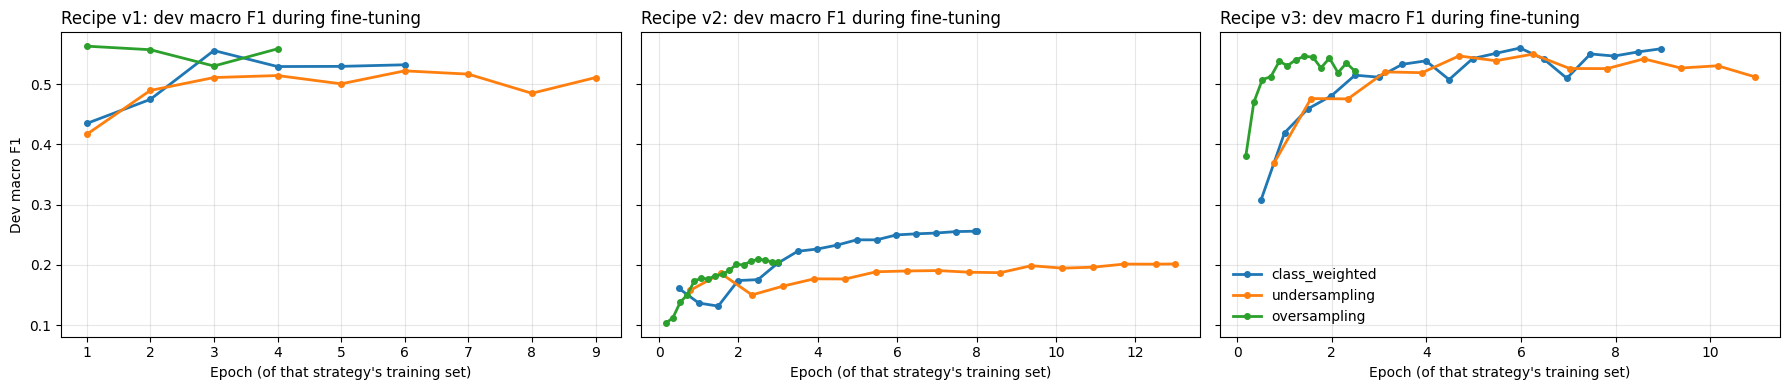

In [7]:
fig, axes = plt.subplots(1, len(RECIPES), figsize=(6 * len(RECIPES), 4), sharey=True)
for ax, recipe_name in zip(axes, RECIPES):
    for strategy in strategies:
        h = pd.DataFrame(histories[f"{recipe_name}/{strategy}"])
        ax.plot(h["epoch"], h["dev_macro_f1"], marker="o", markersize=4, linewidth=2, label=strategy)
    ax.set_title(f"Recipe {recipe_name}: dev macro F1 during fine-tuning", loc="left")
    ax.set_xlabel("Epoch (of that strategy's training set)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Dev macro F1")
axes[-1].legend(frameon=False)
plt.tight_layout()
plt.show()

## 6. Evaluate

=== Dev ===
                  precision    recall  f1-score   support

    Prolongation       0.50      0.55      0.53       251
           Block       0.34      0.36      0.35       291
        SoundRep       0.54      0.48      0.51       200
         WordRep       0.62      0.47      0.54       349
    Interjection       0.60      0.82      0.69       503
NoStutteredWords       0.80      0.73      0.77      1407

        accuracy                           0.65      3001
       macro avg       0.57      0.57      0.56      3001
    weighted avg       0.66      0.65      0.65      3001

Macro AUC-ROC (OVR): 0.8531


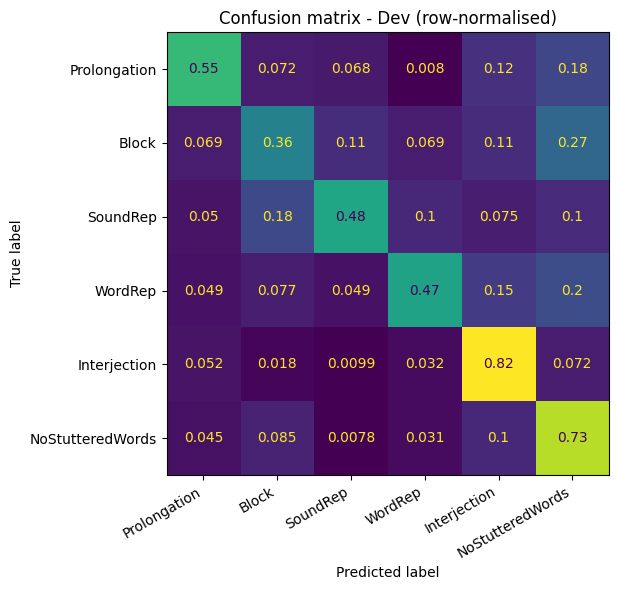

In [8]:
def evaluate(loader, title):
    """Report on every clip in loader and return (true labels, predictions, probabilities)."""
    logits, labels = predict(model, loader)
    preds = logits.argmax(dim=1).numpy()
    probs = torch.softmax(logits, dim=1).numpy()
    report(labels.numpy(), preds, probs, title)
    return labels.numpy(), preds, probs


dev_results = evaluate(dev_loader, "Dev")

=== Test ===
                  precision    recall  f1-score   support

    Prolongation       0.49      0.46      0.48       242
           Block       0.30      0.35      0.32       310
        SoundRep       0.47      0.43      0.45       178
         WordRep       0.65      0.50      0.57       445
    Interjection       0.60      0.85      0.70       532
NoStutteredWords       0.79      0.72      0.76      1514

        accuracy                           0.64      3221
       macro avg       0.55      0.55      0.55      3221
    weighted avg       0.65      0.64      0.64      3221

Macro AUC-ROC (OVR): 0.8493


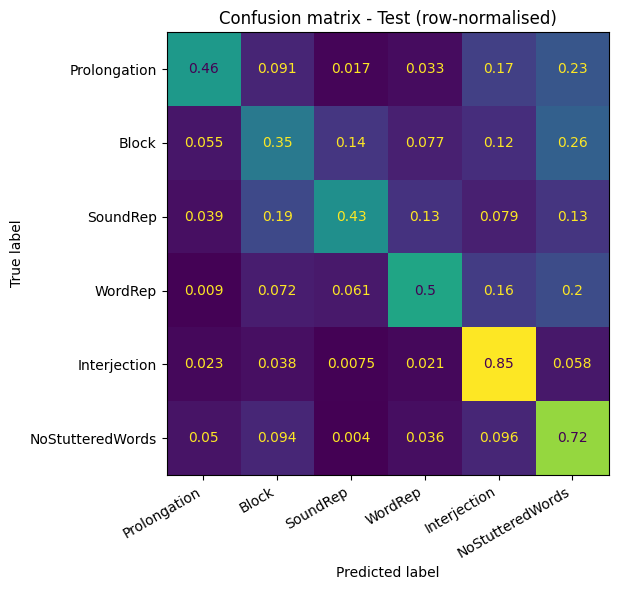

In [9]:
test_results = evaluate(test_loader, "Test")

## 7. Cross-corpus test on UCLASS

The UCLASS clips go through the same waveform extraction and are scored with the final model. No
UCLASS clip was used for training or for choosing the recipe or strategy.

Xwav_uclass_wav2vec_wav_v1: loaded from cache


UCLASS waveforms: (4712, 48000)


=== UCLASS ===
                  precision    recall  f1-score   support

    Prolongation       0.14      0.08      0.10       443
           Block       0.26      0.15      0.19      1132
        SoundRep       0.12      0.14      0.13       720
         WordRep       0.03      0.48      0.05        54
    Interjection       0.11      0.55      0.19       141
NoStutteredWords       0.55      0.34      0.42      2222

        accuracy                           0.25      4712
       macro avg       0.20      0.29      0.18      4712
    weighted avg       0.36      0.25      0.28      4712

Macro AUC-ROC (OVR): 0.5807


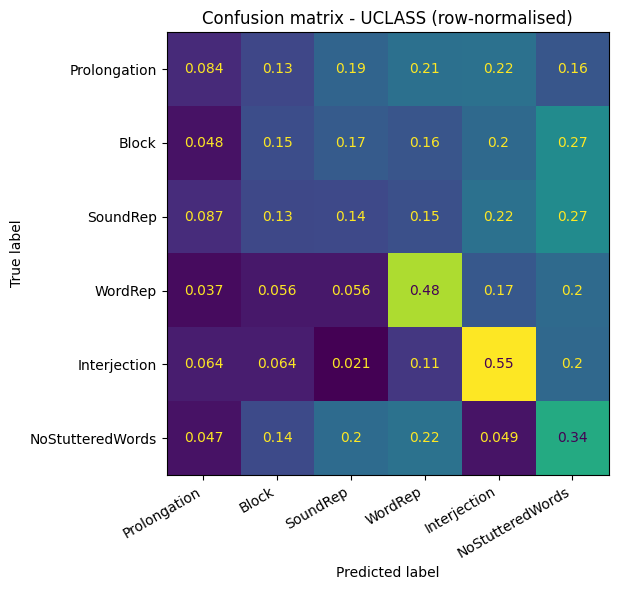

In [10]:
uclass_meta = load_uclass_meta()
wav_uclass, y_uclass = cached("Xwav_uclass_wav2vec_wav_v1", "ywav_uclass_wav2vec_wav_v1",
                              lambda: (np.stack(list(uclass_clips(uclass_meta))), uclass_meta["label"].to_numpy()))
assert len(uclass_meta) == len(y_uclass), "rerun UCLASS_Preprocessing.ipynb"
print(f"UCLASS waveforms: {wav_uclass.shape}")

uclass_loader = make_loader(wav_uclass, y_uclass)
uclass_results = evaluate(uclass_loader, "UCLASS")

## 8. Child vs adult

Same as Models 2 and 3: macro F1 per age group with a 95% bootstrap CI. Child results are
exploratory because there are fewer than 20 child speakers.

In [11]:
_, uclass_preds, _ = uclass_results
age_group_report(y_uclass, uclass_preds, uclass_meta)


=== UCLASS - Child (<18) (n=1087) ===
                  precision    recall  f1-score   support

    Prolongation       0.06      0.03      0.04       150
           Block       0.28      0.20      0.23       270
        SoundRep       0.16      0.11      0.13       236
         WordRep       0.15      0.50      0.22        38
    Interjection       0.17      0.53      0.26        70
NoStutteredWords       0.49      0.47      0.48       323

        accuracy                           0.27      1087
       macro avg       0.22      0.31      0.23      1087
    weighted avg       0.27      0.27      0.26      1087



Macro F1: 0.2275  (95% bootstrap CI: [0.2027, 0.2516])

=== UCLASS - Adult (18+) (n=3625) ===
                  precision    recall  f1-score   support

    Prolongation       0.17      0.11      0.13       293
           Block       0.25      0.13      0.17       862
        SoundRep       0.11      0.15      0.12       484
         WordRep       0.01      0.44      0.02        16
    Interjection       0.09      0.56      0.15        71
NoStutteredWords       0.57      0.32      0.41      1899

        accuracy                           0.24      3625
       macro avg       0.20      0.29      0.17      3625
    weighted avg       0.39      0.24      0.29      3625



Macro F1: 0.1680  (95% bootstrap CI: [0.1551, 0.1815])


## 9. Save predictions

Used by `Results_Summary.ipynb` to compare the three models without retraining. The training curves
of all 9 runs are saved as well.

In [12]:
save_predictions("model1_wav2vec2_preds.npz",
                 {"dev": dev_results, "test": test_results, "uclass": uclass_results},
                 dev_f1s, best_config)

history_table = pd.concat([pd.DataFrame(h).assign(recipe=key.split("/")[0], strategy=key.split("/")[1])
                           for key, h in histories.items()])
history_table.to_csv(RESULTS_DIR / "model1_wav2vec2_training_history.csv", index=False)

Saved results\model1_wav2vec2_preds.npz
